# Intrusion Detection with NSL-KDD

This notebook compares ANFIS and Decision Tree classifiers for binary intrusion detection. A normal connection is labelled `0`; every attack type is labelled `1`.

## Experiments

1. **ANFIS:** all 41 original traffic attributes.
2. **Fisher Score + ANFIS:** the 17 highest-ranked original attributes.
3. **Decision Tree:** all 41 original traffic attributes.
4. **Fisher Score + Decision Tree:** the same 17 selected attributes.

The categorical attributes `protocol_type`, `service`, and `flag` are one-hot encoded, and numeric attributes are scaled. The difficulty column is not used as a model input.

## Data and evaluation

The notebook uses `KDDTrain+` for fitting and validation, and `KDDTest+` for the final measurements. Two separate validation groups are used: one for selecting model settings and one for choosing the decision threshold. The primary threshold policy maximizes attack recall while keeping validation false-positive rate at or below 3%. The test false-positive rate is measured separately and may be higher or lower.

## Run the notebook

Run the cells from top to bottom. The dataset is downloaded automatically when the files are not found beside the notebook or script. The model search can take several minutes, depending on the runtime and whether a GPU is available.


## 1. Install the required packages

Run this cell once in the current Colab or Jupyter runtime.


In [3]:
%pip -q install numpy pandas scikit-learn matplotlib torch requests


Note: you may need to restart the kernel to use updated packages.


## 2. Prepare the experiment script

The next cell writes the Python script used for the experiments. The model definitions and training procedure are kept in the script; the notebook runs it in the following step.




This cell loads the dataset, fits the four models, evaluates them on `KDDTest+`, and saves the comparison tables and figures. Keep the runtime active until it finishes.


Device: cuda
Full KDDTrain+: 125,973 rows; official KDDTest+: 22,544 rows
Binary labels: normal=0, attack=1. Difficulty column excluded from model inputs.
Shared fitting rows: 106,463
Model-selection validation rows: 8,412; threshold-calibration rows: 11,098; official test rows: 22,544
Fit distribution: normal=58,982, attack=47,481
Model-selection attack families (not present in fit): back, buffer_overflow, portsweep, warezclient
Threshold-calibration attack families (not present in fit or model-selection set): guess_passwd, rootkit, satan, smurf
Attack-family labels are used only for splitting. All classifiers receive binary targets.

Top 17 original attributes by fitting-only Fisher ranking:
                 feature  fisher_score
           same_srv_rate      2.350204
                    flag      2.192987
dst_host_srv_serror_rate      1.423657
         srv_serror_rate      1.371977
             serror_rate      1.369959
    dst_host_serror_rate      1.368336
      dst_host_srv_count

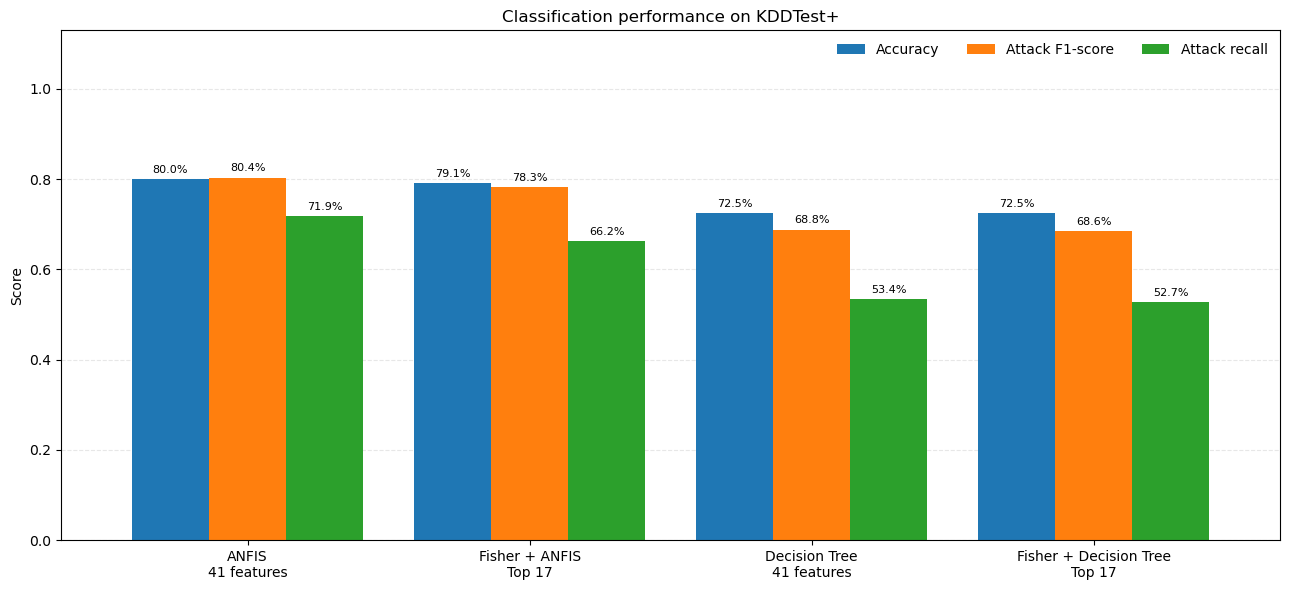

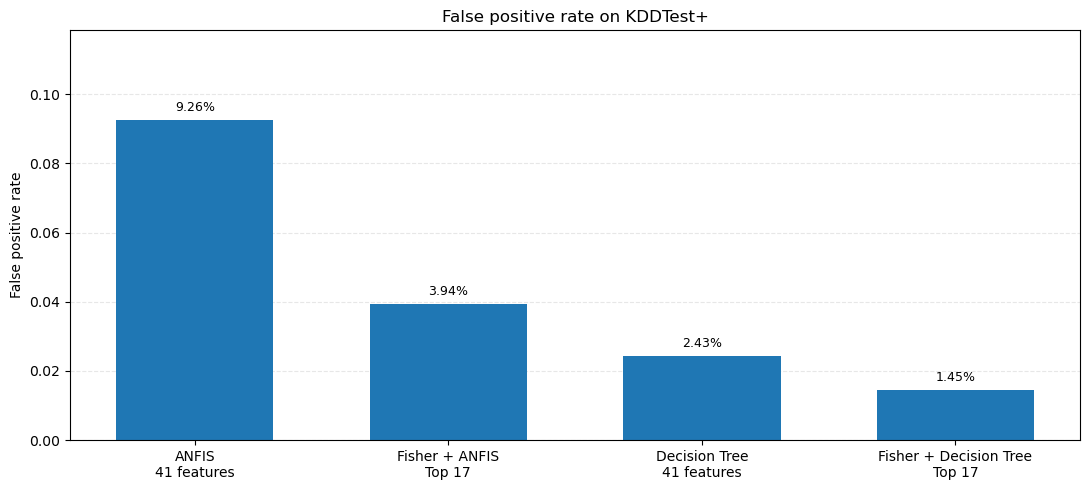

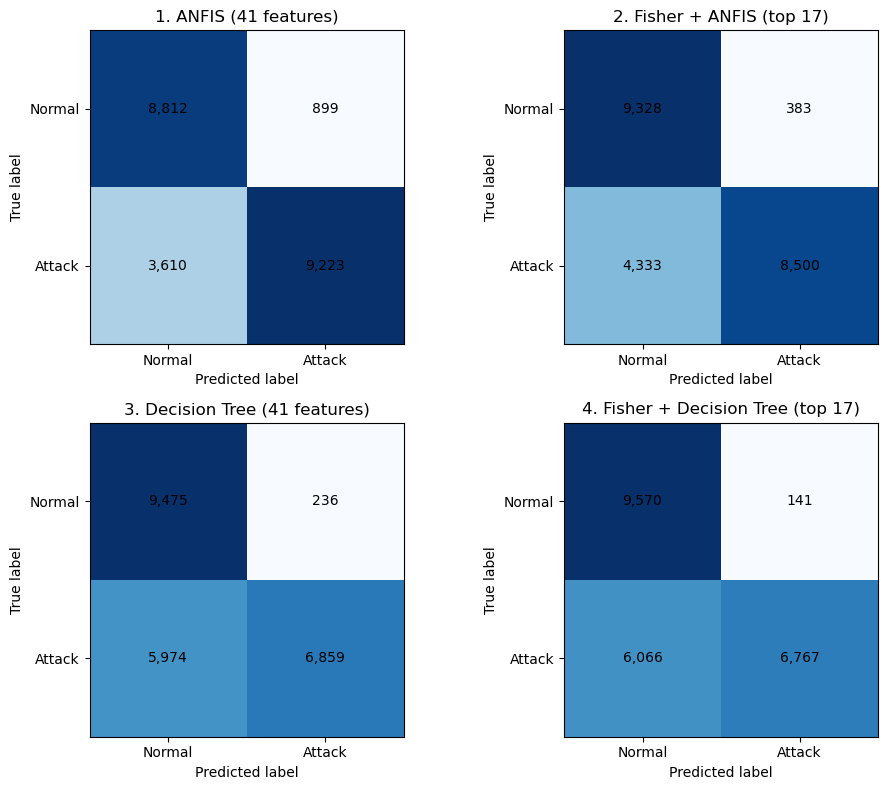


Saved outputs to: results/
CSV files: four_experiment_results.csv, operating_point_analysis.csv, top17_features.csv
Figures: metric_comparison.png, fpr_comparison.png, confusion_matrices.png


In [4]:
from __future__ import annotations

import copy
import io
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from sklearn.cluster import MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
FIT_SAMPLE_MAX = None  # use all fitting rows; validation and test remain separate
ANFIS_SEARCH_SAMPLE = 10000
OUTPUT_DIR = Path("results")
PRIMARY_VALIDATION_FPR_CAP = 0.03
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 2))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# NSL-KDD has 41 input attributes, followed by attack label and difficulty level.
FEATURES = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
]
ALL_COLUMNS = FEATURES + ["label", "difficulty"]
CATEGORICAL = ["protocol_type", "service", "flag"]

DATA_URL_CANDIDATES = {
    "train": [
        "https://raw.githubusercontent.com/HoaNP/NSL-KDD-DataSet/master/KDDTrain%2B.txt",
        "https://raw.githubusercontent.com/HoaNP/NSL-KDD-DataSet/master/KDDTrain+.txt",
    ],
    "test": [
        "https://raw.githubusercontent.com/HoaNP/NSL-KDD-DataSet/master/KDDTest%2B.txt",
        "https://raw.githubusercontent.com/HoaNP/NSL-KDD-DataSet/master/KDDTest+.txt",
    ],
}


def load_nsl_kdd_file(urls: list[str]) -> pd.DataFrame:
    """Load a local NSL-KDD text file when available, otherwise download it."""
    is_train = any("train" in url.lower() for url in urls)
    local_names = (
        ["KDDTrain+.txt", "KDDTrain%2B.txt", "KDDTrain+.csv"]
        if is_train else ["KDDTest+.txt", "KDDTest%2B.txt", "KDDTest+.csv"]
    )
    search_dirs = [Path.cwd()]
    checked = set()
    for directory in search_dirs:
        for name in local_names:
            local_path = directory / name
            if str(local_path.resolve()) in checked:
                continue
            checked.add(str(local_path.resolve()))
            if local_path.exists():
                frame = pd.read_csv(local_path, header=None)
                if frame.shape[1] != len(ALL_COLUMNS):
                    raise ValueError(f"Expected {len(ALL_COLUMNS)} columns in {local_path}, found {frame.shape[1]}")
                frame.columns = ALL_COLUMNS
                print(f"Loaded local dataset file: {local_path}")
                return frame

    errors = []
    for url in urls:
        try:
            response = requests.get(url, timeout=90)
            response.raise_for_status()
            frame = pd.read_csv(io.BytesIO(response.content), header=None)
            if frame.shape[1] != len(ALL_COLUMNS):
                raise ValueError(
                    f"Expected {len(ALL_COLUMNS)} columns, found {frame.shape[1]} from {url}"
                )
            frame.columns = ALL_COLUMNS
            return frame
        except Exception as exc:  # try the next URL candidate
            errors.append(f"{url}: {exc}")
    raise RuntimeError(
        "Could not download NSL-KDD. Download KDDTrain+.txt and KDDTest+.txt from "
        "https://github.com/HoaNP/NSL-KDD-DataSet and upload them next to this script.\n"
        + "\n".join(errors)
    )


def binary_labels(frame: pd.DataFrame) -> np.ndarray:
    labels = frame["label"].astype(str).str.strip().str.rstrip(".").str.lower()
    return (labels != "normal").astype(np.int64).to_numpy()


def fisher_1d(values: np.ndarray, y: np.ndarray) -> float:
    """Class-separation / within-class-scatter score for one numeric column."""
    x = np.asarray(values, dtype=np.float64).reshape(-1)
    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
    overall_mean = float(np.mean(x))
    between = 0.0
    within = 0.0
    for cls in np.unique(y):
        xc = x[y == cls]
        if len(xc) == 0:
            continue
        mean_c = float(np.mean(xc))
        between += len(xc) * (mean_c - overall_mean) ** 2
        within += float(np.sum((xc - mean_c) ** 2))
    return float(between / (within + 1e-12))


def rank_original_features_with_fisher(X_fit: pd.DataFrame, y_fit: np.ndarray) -> pd.DataFrame:
    """Rank original attributes. Category attributes remain one feature each in ranking.

    For protocol_type/service/flag, one-hot encode that single original attribute and
    aggregate its dummy-column Fisher scores using the maximum one-vs-rest score.
    The ranking sees fitting data only, never validation or official test labels.
    """
    rows = []
    for col in FEATURES:
        s = X_fit[col]
        if col in CATEGORICAL:
            dummy = pd.get_dummies(s.astype(str), dtype=np.float32)
            scores = [fisher_1d(dummy.iloc[:, j].to_numpy(), y_fit) for j in range(dummy.shape[1])]
            score = max(scores) if scores else 0.0
        else:
            numeric = pd.to_numeric(s, errors="coerce").fillna(0).to_numpy()
            score = fisher_1d(numeric, y_fit)
        rows.append({"feature": col, "fisher_score": score})
    return pd.DataFrame(rows).sort_values(
        "fisher_score", ascending=False, kind="stable"
    ).reset_index(drop=True)


def make_one_hot_encoder() -> OneHotEncoder:
    """Support recent and older scikit-learn versions."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False, dtype=np.float32)


def make_preprocessor(features: list[str]) -> ColumnTransformer:
    numeric_cols = [col for col in features if col not in CATEGORICAL]
    categorical_cols = [col for col in features if col in CATEGORICAL]
    transformers = []
    if numeric_cols:
        transformers.append(("numeric", StandardScaler(), numeric_cols))
    if categorical_cols:
        transformers.append(("categorical", make_one_hot_encoder(), categorical_cols))
    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0,
        verbose_feature_names_out=False,
    )


def prepare_feature_path(features: list[str], X_fit_raw, X_val_raw, X_test_raw, X_threshold_raw):
    """Fit preprocessing on fitting rows, transform both validation sets and test."""
    preprocessor = make_preprocessor(features)
    x_fit = np.asarray(preprocessor.fit_transform(X_fit_raw[features]), dtype=np.float32)
    x_val = np.asarray(preprocessor.transform(X_val_raw[features]), dtype=np.float32)
    x_threshold = np.asarray(preprocessor.transform(X_threshold_raw[features]), dtype=np.float32)
    x_test = np.asarray(preprocessor.transform(X_test_raw[features]), dtype=np.float32)
    x_fit = np.nan_to_num(x_fit, nan=0.0, posinf=0.0, neginf=0.0)
    x_val = np.nan_to_num(x_val, nan=0.0, posinf=0.0, neginf=0.0)
    x_threshold = np.nan_to_num(x_threshold, nan=0.0, posinf=0.0, neginf=0.0)
    x_test = np.nan_to_num(x_test, nan=0.0, posinf=0.0, neginf=0.0)
    return x_fit, x_val, x_threshold, x_test, preprocessor

class SugenoANFIS(torch.nn.Module):
    """Feature-weighted first-order Sugeno ANFIS for binary classification.

    The learned feature relevance vector changes the contribution of each encoded
    input to fuzzy-rule activation. Consequents remain local linear Sugeno functions.
    This is an enhanced ANFIS variant, not a claim that relevance weighting is part of
    every classical ANFIS definition.
    """
    def __init__(self, centers: np.ndarray, initial_sigma: np.ndarray):
        super().__init__()
        centers_t = torch.as_tensor(centers, dtype=torch.float32)
        sigma_t = torch.as_tensor(initial_sigma, dtype=torch.float32)
        self.centers = torch.nn.Parameter(centers_t.clone())
        self.log_sigma = torch.nn.Parameter(torch.log(sigma_t.clamp(min=0.20)).clone())
        self.log_temperature = torch.nn.Parameter(torch.tensor(np.log(0.20), dtype=torch.float32))
        n_rules, n_features = centers.shape
        # Start with equal relevance (softmax logits all zero; mean relevance is 1).
        self.log_feature_relevance = torch.nn.Parameter(torch.zeros(n_features, dtype=torch.float32))
        self.consequents = torch.nn.Parameter(torch.zeros((n_rules, n_features + 1)), requires_grad=False)

    def feature_relevance(self) -> torch.Tensor:
        # Relevance weights sum to number of input dimensions, so the starting scale
        # matches the previous mean-squared-distance formulation.
        n_features = self.log_feature_relevance.numel()
        return torch.softmax(self.log_feature_relevance, dim=0) * n_features

    def firing_strengths(self, x: torch.Tensor) -> torch.Tensor:
        sigma = torch.exp(self.log_sigma).clamp(min=0.20, max=4.0)
        normalized = (x.unsqueeze(1) - self.centers.unsqueeze(0)) / sigma.unsqueeze(0)
        relevance = self.feature_relevance().clamp(min=1e-4, max=float(x.shape[1]))
        log_firing = -0.5 * torch.mean(normalized.square() * relevance.view(1, 1, -1), dim=2)
        temperature = torch.exp(self.log_temperature).clamp(min=0.04, max=1.5)
        return torch.softmax(log_firing / temperature, dim=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        firing = self.firing_strengths(x)
        x_aug = torch.cat([x, torch.ones((x.shape[0], 1), device=x.device)], dim=1)
        local_outputs = x_aug @ self.consequents.T
        return torch.sum(firing * local_outputs, dim=1)


def _as_tensor_batches(x: np.ndarray, y: np.ndarray | None = None, batch_size: int = 2048):
    """Yield device tensors in batches to keep LSE memory bounded."""
    for start_i in range(0, len(x), batch_size):
        xb = torch.as_tensor(x[start_i:start_i + batch_size], dtype=torch.float32, device=DEVICE)
        if y is None:
            yield xb
        else:
            yb = torch.as_tensor(y[start_i:start_i + batch_size], dtype=torch.float32, device=DEVICE)
            yield xb, yb


def fit_sugeno_consequents(
    model: SugenoANFIS,
    X: np.ndarray,
    y: np.ndarray,
    ridge_alpha: float = 0.1,
    batch_size: int = 2048,
) -> None:
    """Estimate each rule's local linear consequent with regularized weighted least squares.

    Each rule emphasizes rows with high normalized firing strength. Sufficient statistics
    are accumulated batchwise, avoiding a huge (samples x rules*features) design matrix.
    """
    n_rules = model.centers.shape[0]
    n_cols = X.shape[1] + 1
    gram = [torch.zeros((n_cols, n_cols), dtype=torch.float32, device=DEVICE) for _ in range(n_rules)]
    rhs = [torch.zeros((n_cols,), dtype=torch.float32, device=DEVICE) for _ in range(n_rules)]
    weight_sums = [torch.zeros((), dtype=torch.float32, device=DEVICE) for _ in range(n_rules)]

    model.eval()
    with torch.no_grad():
        for xb, yb in _as_tensor_batches(X, y, batch_size):
            firing = model.firing_strengths(xb)
            xa = torch.cat([xb, torch.ones((len(xb), 1), device=DEVICE)], dim=1)
            for r in range(n_rules):
                # Standard weighted LSE: each sample contributes in proportion to its
                # normalized rule activation. Tiny floors prevent empty-rule matrices.
                w = firing[:, r].clamp(min=1e-6)
                gram[r].add_(xa.T @ (xa * w[:, None]))
                rhs[r].add_(xa.T @ (w * yb))
                weight_sums[r].add_(w.sum())

        eye = torch.eye(n_cols, dtype=torch.float32, device=DEVICE)
        for r in range(n_rules):
            scale = weight_sums[r].clamp(min=1.0)
            g = gram[r] / scale
            b = rhs[r] / scale
            reg = eye * float(ridge_alpha)
            # Intercept should be regularized much less than the feature coefficients.
            reg[-1, -1] = float(ridge_alpha) * 1e-3
            try:
                coef = torch.linalg.solve(g + reg, b)
            except RuntimeError:
                coef = torch.linalg.lstsq(g + reg, b.unsqueeze(1)).solution.squeeze(1)
            model.consequents[r].copy_(coef)


def fit_anfis(
    X_fit: np.ndarray,
    y_fit: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    n_rules: int = 6,
    max_epochs: int = 36,
    patience: int = 7,
    batch_size: int = 512,
    ridge_alpha: float = 0.1,
    lse_interval: int = 2,
    verbose: bool = True,
):
    """Train feature-weighted ANFIS with hybrid learning and validation-F1 stopping."""
    start_time = time.perf_counter()
    config_seed = SEED + int(n_rules * 13) + int(round(ridge_alpha * 100000))
    np.random.seed(config_seed)
    torch.manual_seed(config_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(config_seed)
    rng = np.random.default_rng(config_seed)
    init_rows = min(10000, len(X_fit))
    if len(X_fit) > init_rows:
        # Stratified subsampling preserves both target classes for premise initialization.
        init_idx, _ = train_test_split(
            np.arange(len(X_fit)), train_size=init_rows,
            stratify=y_fit, random_state=config_seed,
        )
        cluster_data = X_fit[init_idx]
        cluster_y = y_fit[init_idx]
    else:
        cluster_data = X_fit
        cluster_y = y_fit

    # Class-aware rule initialization: cluster normal and attack samples separately,
    # then combine the centers. This is supervised initialization, not test leakage:
    # only fitting labels are used, and all consequent/premise updates remain train-only.
    rules_per_class = {0: n_rules // 2, 1: n_rules - (n_rules // 2)}
    center_rows = []
    sigma_rows = []
    for class_label in (0, 1):
        class_data = cluster_data[cluster_y == class_label]
        n_class_rules = int(rules_per_class[class_label])
        if len(class_data) < n_class_rules:
            raise ValueError(
                f"Not enough fitting examples for class {class_label} to initialize "
                f"{n_class_rules} ANFIS rules."
            )
        class_clusterer = MiniBatchKMeans(
            n_clusters=n_class_rules, n_init=5, max_iter=120,
            batch_size=min(2048, max(256, len(class_data))),
            random_state=config_seed + 101 * class_label,
        )
        class_labels = class_clusterer.fit_predict(class_data)
        class_global_std = np.std(class_data, axis=0).astype(np.float32)
        for r in range(n_class_rules):
            members = class_data[class_labels == r]
            local_std = (
                np.std(members, axis=0).astype(np.float32)
                if len(members) > 2 else class_global_std
            )
            center_rows.append(class_clusterer.cluster_centers_[r].astype(np.float32))
            # Width floor avoids collapsed Gaussian membership functions, especially
            # on one-hot categorical dimensions.
            sigma_rows.append(np.clip(np.maximum(local_std, 0.30) * 1.25, 0.30, 3.5))
    centers = np.vstack(center_rows).astype(np.float32)
    initial_sigma = np.vstack(sigma_rows).astype(np.float32)

    model = SugenoANFIS(centers, initial_sigma).to(DEVICE)
    optimizer = torch.optim.Adam(
        [
            {"params": [model.centers], "lr": 0.0012},
            {"params": [model.log_sigma], "lr": 0.0018},
            {"params": [model.log_temperature], "lr": 0.0007},
            {"params": [model.log_feature_relevance], "lr": 0.0030},
        ],
        weight_decay=1e-5,
    )
    x_fit_t = torch.as_tensor(X_fit, dtype=torch.float32, device=DEVICE)
    y_fit_t = torch.as_tensor(y_fit, dtype=torch.float32, device=DEVICE)
    x_val_t = torch.as_tensor(X_val, dtype=torch.float32, device=DEVICE)

    fit_sugeno_consequents(model, X_fit, y_fit, ridge_alpha=ridge_alpha, batch_size=2048)
    best_key = (-1.0, -1.0, 1.0, float("inf"))
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0
    history = []

    for epoch in range(1, max_epochs + 1):
        model.train()
        order = torch.randperm(len(x_fit_t), device=DEVICE)
        total_loss, total_seen = 0.0, 0
        for start_i in range(0, len(order), batch_size):
            idx = order[start_i:start_i + batch_size]
            xb, yb = x_fit_t[idx], y_fit_t[idx]
            optimizer.zero_grad(set_to_none=True)
            scores = model(xb)
            mse = torch.mean((scores - yb).square())
            # Weak shrinkage keeps feature relevance from collapsing onto one column.
            relevance_penalty = torch.mean(model.log_feature_relevance.square())
            loss = mse + 5e-4 * relevance_penalty
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                [model.centers, model.log_sigma, model.log_temperature,
                 model.log_feature_relevance], max_norm=3.0
            )
            optimizer.step()
            with torch.no_grad():
                model.log_sigma.clamp_(min=float(np.log(0.20)), max=float(np.log(4.0)))
                model.log_temperature.clamp_(min=float(np.log(0.04)), max=float(np.log(1.5)))
                model.centers.clamp_(min=-7.0, max=7.0)
                model.log_feature_relevance.clamp_(min=-5.0, max=5.0)
            total_loss += float(loss.detach().cpu()) * len(idx)
            total_seen += len(idx)

        if epoch % max(1, lse_interval) == 0 or epoch == max_epochs:
            fit_sugeno_consequents(model, X_fit, y_fit, ridge_alpha=ridge_alpha, batch_size=2048)

        model.eval()
        with torch.no_grad():
            val_scores_t = model(x_val_t)
            val_scores = val_scores_t.detach().cpu().numpy()
            val_mse = float(torch.mean((val_scores_t - torch.as_tensor(y_val, dtype=torch.float32, device=DEVICE)).square()).cpu())
        val_threshold = threshold_for_max_recall_at_fpr(y_val, val_scores, PRIMARY_VALIDATION_FPR_CAP)
        val_metrics = compute_metrics(y_val, (val_scores >= val_threshold).astype(np.int64))
        train_loss = total_loss / max(total_seen, 1)
        history.append({
            "epoch": epoch, "train_loss": train_loss, "val_mse": val_mse,
            "val_F1_attack": val_metrics["F1_attack"],
            "val_recall_TPR": val_metrics["recall_TPR"], "val_FPR": val_metrics["FPR"],
            "val_threshold": val_threshold,
            "temperature": float(torch.exp(model.log_temperature).detach().cpu()),
            "effective_feature_count": float(torch.exp(model.log_feature_relevance).detach().cpu().std().item()),
        })
        # Match model selection to the intended classifier use, rather than MSE alone.
        key = (val_metrics["F1_attack"], val_metrics["recall_TPR"], -val_metrics["FPR"], -val_mse)
        if verbose:
            print(f"    ANFIS epoch {epoch:02d}: val_F1={val_metrics['F1_attack']:.4f}, "
                  f"recall={val_metrics['recall_TPR']:.4f}, FPR={val_metrics['FPR']:.4f}, "
                  f"val_MSE={val_mse:.4f}")
        if key > best_key:
            best_key = key
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                if verbose:
                    print("    Early stopping: validation F1/recall no longer improves.")
                break

    model.load_state_dict(best_state)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start_time
    return model, elapsed, best_epoch, pd.DataFrame(history)


def anfis_predict_score(model: SugenoANFIS, X: np.ndarray, batch_size: int = 2048) -> np.ndarray:
    """Return the continuous Sugeno score (not assumed to be a calibrated probability)."""
    model.eval()
    scores = []
    with torch.no_grad():
        for xb in _as_tensor_batches(X, None, batch_size):
            scores.append(model(xb).detach().cpu().numpy())
    return np.concatenate(scores) if scores else np.array([], dtype=float)


def best_f1_threshold(y_true: np.ndarray, scores: np.ndarray) -> float:
    """Pick an F1-optimal threshold on validation scores only, for both ANFIS and DT."""
    from sklearn.metrics import precision_recall_curve
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    if len(thresholds) == 0:
        return float(np.median(scores)) if len(scores) else 0.5
    denom = precision[:-1] + recall[:-1]
    f1_values = np.divide(2 * precision[:-1] * recall[:-1], denom,
                          out=np.zeros_like(denom), where=denom > 0)
    best = np.flatnonzero(f1_values >= np.max(f1_values) - 1e-12)
    # On a tie, choose the highest threshold, which is typically the less trigger-happy option.
    return float(thresholds[best[-1]])


def threshold_for_max_recall_at_fpr(y_true: np.ndarray, scores: np.ndarray, max_fpr: float) -> float:
    """Maximize validation recall subject to a validation false-positive-rate cap.

    If no positive prediction meets the constraint, return a finite threshold just above
    the largest calibration score (the ROC curve's +inf sentinel means "predict none").
    The cap is a validation design target, not a guarantee of the same test FPR.
    """
    from sklearn.metrics import roc_curve
    scores = np.asarray(scores, dtype=float)
    fpr, tpr, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    valid = np.flatnonzero(fpr <= float(max_fpr) + 1e-12)
    if len(valid) == 0:
        return float(np.nextafter(np.max(scores), np.inf)) if len(scores) else 0.5
    best_tpr = float(np.max(tpr[valid]))
    tied = valid[tpr[valid] >= best_tpr - 1e-12]
    idx = tied[int(np.argmax(thresholds[tied]))]
    threshold = float(thresholds[idx])
    if not np.isfinite(threshold):
        threshold = float(np.nextafter(np.max(scores), np.inf)) if len(scores) else 0.5
    return threshold

def tune_anfis(
    X_fit: np.ndarray,
    y_fit: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_threshold: np.ndarray,
    y_threshold: np.ndarray,
    path_name: str,
    out_dir: Path,
):
    """Choose ANFIS structure on one held-out-family set and threshold on another."""
    search_n = min(ANFIS_SEARCH_SAMPLE, len(X_fit))
    if len(X_fit) > search_n:
        X_search, _, y_search, _ = train_test_split(
            X_fit, y_fit, train_size=search_n, stratify=y_fit, random_state=SEED + 7
        )
    else:
        X_search, y_search = X_fit, y_fit

    trial_rows = []
    configs = [(rules, alpha) for rules in (4, 6, 8, 12, 16, 24, 32)
               for alpha in (0.00001, 0.0001, 0.001, 0.01)]
    print(f"\nANFIS model-selection search for {path_name}: {len(configs)} configurations")
    for n_rules, alpha in configs:
        model, seconds, best_epoch, history = fit_anfis(
            X_search, y_search, X_val, y_val,
            n_rules=n_rules, max_epochs=24, patience=6, batch_size=768,
            ridge_alpha=alpha, lse_interval=1, verbose=False,
        )
        val_scores = anfis_predict_score(model, X_val)
        model_val_threshold = threshold_for_max_recall_at_fpr(y_val, val_scores, PRIMARY_VALIDATION_FPR_CAP)
        val_pred = (val_scores >= model_val_threshold).astype(np.int64)
        val_metrics = compute_metrics(y_val, val_pred)
        val_mse = float(np.mean((val_scores - y_val) ** 2))
        trial_rows.append({
            "feature_path": path_name, "n_rules": n_rules, "ridge_alpha": alpha,
            "search_fit_seconds": seconds, "best_epoch": best_epoch,
            "model_selection_threshold": model_val_threshold, "model_selection_MSE": val_mse,
            **{f"model_selection_{k}": v for k, v in val_metrics.items()},
        })
        print(f"  rules={n_rules:2d}, ridge={alpha:g}: selection_F1={val_metrics['F1_attack']:.4f}, "
              f"recall={val_metrics['recall_TPR']:.4f}, best_epoch={best_epoch}")

    trial_df = pd.DataFrame(trial_rows).sort_values(
        ["model_selection_F1_attack", "model_selection_recall_TPR", "model_selection_FPR", "model_selection_MSE"],
        ascending=[False, False, True, True], kind="stable"
    ).reset_index(drop=True)
    safe_name = path_name.lower().replace(" ", "_").replace("+", "plus")
    # Tuning trials are used to select the model but are not exported.
    best = trial_df.iloc[0]
    best_rules, best_alpha = int(best["n_rules"]), float(best["ridge_alpha"])
    print(f"  Selected on model-selection families: rules={best_rules}, ridge={best_alpha:g}, "
          f"selection F1={best['model_selection_F1_attack']:.4f}")

    final_model, final_seconds, best_epoch, history = fit_anfis(
        X_fit, y_fit, X_val, y_val,
        n_rules=best_rules, max_epochs=64, patience=10, batch_size=768,
        ridge_alpha=best_alpha, lse_interval=1, verbose=True,
    )
    # Architecture/epoch selection validation is distinct from threshold calibration.
    selection_scores = anfis_predict_score(final_model, X_val)
    selection_threshold = threshold_for_max_recall_at_fpr(y_val, selection_scores, PRIMARY_VALIDATION_FPR_CAP)
    selection_metrics = compute_metrics(y_val, (selection_scores >= selection_threshold).astype(np.int64))
    threshold_scores = anfis_predict_score(final_model, X_threshold)
    f1max_threshold = best_f1_threshold(y_threshold, threshold_scores)
    f1max_metrics = compute_metrics(y_threshold, (threshold_scores >= f1max_threshold).astype(np.int64))
    final_threshold = threshold_for_max_recall_at_fpr(
        y_threshold, threshold_scores, PRIMARY_VALIDATION_FPR_CAP
    )
    threshold_metrics = compute_metrics(y_threshold, (threshold_scores >= final_threshold).astype(np.int64))

    relevance = final_model.feature_relevance().detach().cpu().numpy()
    # Feature relevance is retained in the fitted model; only report-level tables are saved.
    meta = {
        "tuning_seconds": float(trial_df["search_fit_seconds"].sum()),
        "best_n_rules": best_rules,
        "best_ridge_alpha": best_alpha,
        "best_epoch": best_epoch,
        "validation_threshold": final_threshold,
        "validation_F1_attack": threshold_metrics["F1_attack"],
        "validation_recall_TPR": threshold_metrics["recall_TPR"],
        "validation_FPR": threshold_metrics["FPR"],
        "model_selection_validation_F1": selection_metrics["F1_attack"],
        "model_selection_validation_recall": selection_metrics["recall_TPR"],
        "model_selection_validation_FPR": selection_metrics["FPR"],
        "threshold_calibration_F1": threshold_metrics["F1_attack"],
        "threshold_calibration_recall": threshold_metrics["recall_TPR"],
        "threshold_calibration_FPR": threshold_metrics["FPR"],
        "primary_threshold_policy": "max recall subject to calibration FPR <= 3%",
        "threshold_calibration_F1max_threshold": f1max_threshold,
        "threshold_calibration_F1max_F1": f1max_metrics["F1_attack"],
        "threshold_calibration_F1max_recall": f1max_metrics["recall_TPR"],
        "threshold_calibration_F1max_FPR": f1max_metrics["FPR"],
        "learning_curve": history,
        "training_seconds": final_seconds,
        "feature_relevance_std": float(np.std(relevance)),
    }
    return final_model, meta

def tune_decision_tree(X_fit, y_fit, X_val, y_val, X_threshold, y_threshold, path_name: str, out_dir: Path):
    """Tune tree structure on one validation set; calibrate threshold on a separate one."""
    candidates = []
    trial_rows = []
    search_start = time.perf_counter()
    for criterion in ("gini", "entropy"):
        for max_depth in (None, 20, 40):
            for min_samples_leaf in (1, 2, 5):
                model = DecisionTreeClassifier(
                    criterion=criterion, max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf, random_state=SEED,
                )
                start = time.perf_counter()
                model.fit(X_fit, y_fit)
                seconds = time.perf_counter() - start
                val_scores = model.predict_proba(X_val)[:, 1]
                model_val_threshold = threshold_for_max_recall_at_fpr(y_val, val_scores, PRIMARY_VALIDATION_FPR_CAP)
                val_metrics = compute_metrics(y_val, (val_scores >= model_val_threshold).astype(np.int64))
                candidates.append({
                    "model": model, "criterion": criterion, "max_depth": max_depth,
                    "min_samples_leaf": min_samples_leaf, "fit_seconds": seconds,
                    "selection_threshold": model_val_threshold, "metrics": val_metrics,
                })
                trial_rows.append({
                    "feature_path": path_name, "criterion": criterion,
                    "max_depth": max_depth, "min_samples_leaf": min_samples_leaf,
                    "fit_seconds": seconds, "model_selection_threshold": model_val_threshold,
                    **{f"model_selection_{k}": v for k, v in val_metrics.items()},
                })
    search_seconds = time.perf_counter() - search_start
    safe_name = path_name.lower().replace(" ", "_").replace("+", "plus")
    # Candidate scores are used for model selection but are not exported.
    candidates.sort(key=lambda c: (
        -c["metrics"]["F1_attack"], -c["metrics"]["recall_TPR"], c["metrics"]["FPR"]
    ))
    best = candidates[0]
    print(f"  Selected Decision Tree on model-selection families: criterion={best['criterion']}, "
          f"max_depth={best['max_depth']}, min_samples_leaf={best['min_samples_leaf']}, "
          f"selection F1={best['metrics']['F1_attack']:.4f}")
    threshold_scores = best["model"].predict_proba(X_threshold)[:, 1]
    f1max_threshold = best_f1_threshold(y_threshold, threshold_scores)
    f1max_metrics = compute_metrics(y_threshold, (threshold_scores >= f1max_threshold).astype(np.int64))
    threshold = threshold_for_max_recall_at_fpr(
        y_threshold, threshold_scores, PRIMARY_VALIDATION_FPR_CAP
    )
    threshold_metrics = compute_metrics(y_threshold, (threshold_scores >= threshold).astype(np.int64))
    metadata = {
        "best_n_rules": np.nan, "best_ridge_alpha": np.nan, "best_epoch": np.nan,
        "validation_threshold": threshold,
        "validation_F1_attack": threshold_metrics["F1_attack"],
        "validation_recall_TPR": threshold_metrics["recall_TPR"],
        "validation_FPR": threshold_metrics["FPR"],
        "model_selection_validation_F1": best["metrics"]["F1_attack"],
        "model_selection_validation_recall": best["metrics"]["recall_TPR"],
        "model_selection_validation_FPR": best["metrics"]["FPR"],
        "threshold_calibration_F1": threshold_metrics["F1_attack"],
        "threshold_calibration_recall": threshold_metrics["recall_TPR"],
        "threshold_calibration_FPR": threshold_metrics["FPR"],
        "primary_threshold_policy": "max recall subject to calibration FPR <= 3%",
        "threshold_calibration_F1max_threshold": f1max_threshold,
        "threshold_calibration_F1max_F1": f1max_metrics["F1_attack"],
        "threshold_calibration_F1max_recall": f1max_metrics["recall_TPR"],
        "threshold_calibration_F1max_FPR": f1max_metrics["FPR"],
        "learning_curve": pd.DataFrame(),
        "training_seconds": best["fit_seconds"],
        "tuning_seconds": search_seconds,
        "tree_criterion": best["criterion"], "tree_max_depth": best["max_depth"],
        "tree_min_samples_leaf": best["min_samples_leaf"],
    }
    return best["model"], metadata

def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall_TPR": recall_score(y_true, y_pred, zero_division=0),
        "F1_attack": f1_score(y_true, y_pred, zero_division=0),
        "FPR": fpr,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


def make_attack_family_validation_split(train_df: pd.DataFrame):
    """Build disjoint model-selection and threshold-calibration validation sets.

    Each set contains attack types wholly withheld from fitting, with at least one
    attack family targeted from each major NSL-KDD category when those labels exist.
    The family name is used only to assign rows, never as a model input. A disjoint
    normal subset is added to each validation set, at a fixed approximate normal-to-attack
    ratio of 0.75. The official test set is not inspected.
    """
    raw_attack = train_df["label"].astype(str).str.strip().str.rstrip(".").str.lower()
    y_all = (raw_attack != "normal").astype(np.int64).to_numpy()
    counts = raw_attack[raw_attack != "normal"].value_counts()
    # Preferences are deterministic; only families present in KDDTrain+ are eligible.
    selection_preferences = {
        "DoS": ["back", "teardrop", "pod", "land"],
        "Probe": ["portsweep", "ipsweep", "nmap", "satan"],
        "R2L": ["warezclient", "guess_passwd", "warezmaster", "ftp_write", "imap"],
        "U2R": ["buffer_overflow", "rootkit", "loadmodule", "perl"],
    }
    threshold_preferences = {
        "DoS": ["smurf", "teardrop", "pod", "back", "land"],
        "Probe": ["satan", "nmap", "ipsweep", "portsweep"],
        "R2L": ["guess_passwd", "warezmaster", "imap", "phf", "ftp_write", "warezclient"],
        "U2R": ["rootkit", "loadmodule", "perl", "buffer_overflow"],
    }
    min_count = {"DoS": 20, "Probe": 20, "R2L": 5, "U2R": 5}

    def pick(preferences, already_used):
        chosen = []
        for category, options in preferences.items():
            for label in options:
                count = int(counts.get(label, 0))
                if label not in already_used and count >= min_count[category] and count <= 5000:
                    chosen.append(label)
                    already_used.add(label)
                    break
        return chosen

    used = set()
    selection_types = pick(selection_preferences, used)
    threshold_types = pick(threshold_preferences, used)
    if not selection_types or not threshold_types:
        raise ValueError(
            "Could not form two disjoint attack-family validation sets across categories. "
            "Inspect the attack-label spellings in KDDTrain+."
        )
    selection_attack_idx = np.flatnonzero(raw_attack.isin(selection_types).to_numpy())
    threshold_attack_idx = np.flatnonzero(raw_attack.isin(threshold_types).to_numpy())
    if not len(selection_attack_idx) or not len(threshold_attack_idx):
        raise ValueError("An attack-family validation group unexpectedly contains zero rows.")

    normal_idx = np.flatnonzero((raw_attack == "normal").to_numpy())
    rng = np.random.default_rng(SEED + 501)
    rng.shuffle(normal_idx)
    normal_ratio = 0.75  # fixed approximation; does not inspect official KDDTest+ labels
    n_sel_normal = min(len(normal_idx), max(1000, int(len(selection_attack_idx) * normal_ratio)))
    sel_normal_idx = normal_idx[:n_sel_normal]
    remaining_normal = normal_idx[n_sel_normal:]
    n_thr_normal = min(len(remaining_normal), max(1000, int(len(threshold_attack_idx) * normal_ratio)))
    thr_normal_idx = remaining_normal[:n_thr_normal]

    selection_idx = np.concatenate([selection_attack_idx, sel_normal_idx])
    threshold_idx = np.concatenate([threshold_attack_idx, thr_normal_idx])
    held_mask = np.zeros(len(train_df), dtype=bool)
    held_mask[selection_idx] = True
    held_mask[threshold_idx] = True
    fit_idx = np.flatnonzero(~held_mask)
    rng.shuffle(fit_idx)
    rng.shuffle(selection_idx)
    rng.shuffle(threshold_idx)
    return fit_idx, selection_idx, threshold_idx, y_all, sorted(selection_types), sorted(threshold_types)

def main():
    print(f"Device: {DEVICE}")
    print("Downloading NSL-KDD KDDTrain+ and KDDTest+...")
    train_df = load_nsl_kdd_file(DATA_URL_CANDIDATES["train"])
    test_df = load_nsl_kdd_file(DATA_URL_CANDIDATES["test"])
    y_test = binary_labels(test_df)
    X_test_raw = test_df[FEATURES].copy().reset_index(drop=True)
    print(f"Full KDDTrain+: {len(train_df):,} rows; official KDDTest+: {len(test_df):,} rows")
    print("Binary labels: normal=0, attack=1. Difficulty column excluded from model inputs.")

    fit_idx, select_idx, threshold_idx, y_train_full, selection_attack_types, threshold_attack_types = make_attack_family_validation_split(train_df)
    X_train_all = train_df[FEATURES].copy().reset_index(drop=True)
    X_fit_raw = X_train_all.iloc[fit_idx].copy().reset_index(drop=True)
    X_val_raw = X_train_all.iloc[select_idx].copy().reset_index(drop=True)
    X_threshold_raw = X_train_all.iloc[threshold_idx].copy().reset_index(drop=True)
    y_fit = y_train_full[fit_idx]
    y_val = y_train_full[select_idx]
    y_threshold = y_train_full[threshold_idx]

    if FIT_SAMPLE_MAX is not None and len(X_fit_raw) > FIT_SAMPLE_MAX:
        X_fit_raw, _, y_fit, _ = train_test_split(
            X_fit_raw, y_fit, train_size=FIT_SAMPLE_MAX, stratify=y_fit, random_state=SEED + 13
        )
        X_fit_raw = X_fit_raw.reset_index(drop=True)
    print(f"Shared fitting rows: {len(X_fit_raw):,}")
    print(f"Model-selection validation rows: {len(X_val_raw):,}; threshold-calibration rows: {len(X_threshold_raw):,}; official test rows: {len(X_test_raw):,}")
    print(f"Fit distribution: normal={int((y_fit == 0).sum()):,}, attack={int((y_fit == 1).sum()):,}")
    print("Model-selection attack families (not present in fit): " + ", ".join(selection_attack_types))
    print("Threshold-calibration attack families (not present in fit or model-selection set): " + ", ".join(threshold_attack_types))
    print("Attack-family labels are used only for splitting. All classifiers receive binary targets.")

    fisher_table = rank_original_features_with_fisher(X_fit_raw, y_fit)
    selected17 = fisher_table.head(17)["feature"].tolist()
    out_dir = OUTPUT_DIR
    out_dir.mkdir(parents=True, exist_ok=True)
    # Keep this results folder limited to the three report-ready CSV tables.
    keep_csvs = {"four_experiment_results.csv", "operating_point_analysis.csv", "top17_features.csv"}
    for old_csv in out_dir.glob("*.csv"):
        if old_csv.name not in keep_csvs:
            old_csv.unlink()
    # Remove auxiliary text files from older runs; their details are recorded in the results table.
    for old_text in ("model_selection_attack_types.txt", "threshold_calibration_attack_types.txt"):
        (out_dir / old_text).unlink(missing_ok=True)
    # Save the selected input attributes for the report; the full ranking stays in memory.
    pd.Series(selected17, name="selected_feature").to_csv(out_dir / "top17_features.csv", index=False)
    print("\nTop 17 original attributes by fitting-only Fisher ranking:")
    print(fisher_table.head(17).to_string(index=False))

    feature_sets = {"41 features": FEATURES, "Top 17 Fisher features": selected17}
    encoded = {}
    for path_name, feature_list in feature_sets.items():
        x_fit, x_val, x_threshold, x_test, prep = prepare_feature_path(
            feature_list, X_fit_raw, X_val_raw, X_test_raw, X_threshold_raw
        )
        encoded[path_name] = {
            "X_fit": x_fit, "X_val": x_val, "X_threshold": x_threshold, "X_test": x_test,
            "preprocessor": prep, "original_features": feature_list,
        }
        print(f"\n{path_name}: {len(feature_list)} original attributes -> {x_fit.shape[1]} encoded columns")

    experiments = [
        ("1. ANFIS (41 features)", "ANFIS", "41 features"),
        ("2. Fisher + ANFIS (top 17)", "ANFIS", "Top 17 Fisher features"),
        ("3. Decision Tree (41 features)", "DT", "41 features"),
        ("4. Fisher + Decision Tree (top 17)", "DT", "Top 17 Fisher features"),
    ]
    rows, predictions, score_records, histories, tuning_metadata = [], {}, {}, {}, {}
    for display_name, model_type, path_name in experiments:
        data = encoded[path_name]
        print(f"\n{'=' * 76}\n{display_name}\n{'=' * 76}")
        if model_type == "ANFIS":
            model, meta = tune_anfis(
                data["X_fit"], y_fit, data["X_val"], y_val,
                data["X_threshold"], y_threshold, path_name, out_dir
            )
            score_val = anfis_predict_score(model, data["X_val"])
            score_threshold = anfis_predict_score(model, data["X_threshold"])
            score_test = anfis_predict_score(model, data["X_test"])
            classifier_name, score_type = "Feature-weighted hybrid-learning Sugeno ANFIS", "Sugeno output score"
            histories[display_name] = meta["learning_curve"]
        else:
            model, meta = tune_decision_tree(
                data["X_fit"], y_fit, data["X_val"], y_val,
                data["X_threshold"], y_threshold, path_name, out_dir
            )
            score_val = model.predict_proba(data["X_val"])[:, 1]
            score_threshold = model.predict_proba(data["X_threshold"])[:, 1]
            score_test = model.predict_proba(data["X_test"])[:, 1]
            classifier_name, score_type = "Validation-tuned Decision Tree", "Positive-class probability"

        threshold = float(meta["validation_threshold"])
        y_pred = (score_test >= threshold).astype(np.int64)
        metrics = compute_metrics(y_test, y_pred)
        fit_seconds = float(meta["training_seconds"])
        tuning_seconds = float(meta.get("tuning_seconds", 0.0))
        row = {
            "experiment": display_name,
            "original_features": len(data["original_features"]),
            "encoded_columns": data["X_fit"].shape[1],
            "classifier": classifier_name,
            "validation_threshold": threshold,
            "threshold_applies_to": score_type,
            "primary_threshold_policy": meta.get("primary_threshold_policy", "max recall subject to calibration FPR <= 3%"),
            "calibration_F1max_threshold": meta.get("threshold_calibration_F1max_threshold", np.nan),
            "calibration_F1max_F1": meta.get("threshold_calibration_F1max_F1", np.nan),
            "calibration_F1max_recall": meta.get("threshold_calibration_F1max_recall", np.nan),
            "calibration_F1max_FPR": meta.get("threshold_calibration_F1max_FPR", np.nan),
            "fit_seconds": fit_seconds,
            "tuning_seconds": tuning_seconds,
            "best_n_rules": meta.get("best_n_rules", np.nan),
            "best_ridge_alpha": meta.get("best_ridge_alpha", np.nan),
            "best_epoch": meta.get("best_epoch", np.nan),
            "selected_validation_F1": meta.get("validation_F1_attack", np.nan),
            "selected_validation_recall": meta.get("validation_recall_TPR", np.nan),
            "selected_validation_FPR": meta.get("validation_FPR", np.nan),
            "model_selection_validation_F1": meta.get("model_selection_validation_F1", np.nan),
            "model_selection_validation_recall": meta.get("model_selection_validation_recall", np.nan),
            "model_selection_validation_FPR": meta.get("model_selection_validation_FPR", np.nan),
            "n_fit_rows": len(y_fit),
            "n_model_selection_validation_rows": len(y_val),
            "n_threshold_calibration_rows": len(y_threshold),
            "n_test_rows": len(y_test),
            "model_selection_attack_families_held_out": ";".join(selection_attack_types),
            "threshold_calibration_attack_families_held_out": ";".join(threshold_attack_types),
            "validation_attack_families_held_out": ";".join(sorted(set(selection_attack_types + threshold_attack_types))),
            "feature_relevance_std": meta.get("feature_relevance_std", np.nan),
            "tree_criterion": meta.get("tree_criterion", ""),
            "tree_max_depth": meta.get("tree_max_depth", ""),
            "tree_min_samples_leaf": meta.get("tree_min_samples_leaf", ""),
            **metrics,
        }
        rows.append(row)
        predictions[display_name] = y_pred
        score_records[display_name] = {
            "y_val": y_threshold.copy(), "score_val": np.asarray(score_threshold).copy(),
            "score_selection": np.asarray(score_val).copy(), "score_test": np.asarray(score_test).copy(),
            "primary_threshold": threshold,
            "f1_threshold": float(meta.get("threshold_calibration_F1max_threshold", best_f1_threshold(y_threshold, score_threshold))),
        }
        tuning_metadata[display_name] = {k: v for k, v in meta.items() if k != "learning_curve"}
        print(f"Threshold calibrated on disjoint attack families: {threshold:.6f} ({score_type})")
        print(f"Final fit time: {fit_seconds:.2f}s; tuning time: {tuning_seconds:.2f}s")
        if model_type == "ANFIS":
            print(f"Selected ANFIS rules={meta['best_n_rules']}, ridge={meta['best_ridge_alpha']}, best epoch={meta['best_epoch']}")
        else:
            print(f"Selected DT: criterion={meta['tree_criterion']}, depth={meta['tree_max_depth']}, min_leaf={meta['tree_min_samples_leaf']}")
        print(pd.Series(metrics).to_string())
        print("\nOfficial KDDTest+ classification report:")
        print(classification_report(y_test, y_pred, target_names=["Normal (0)", "Attack (1)"], zero_division=0))

    operating_rows = []
    operating_policies = [
        ("threshold_F1_max_on_disjoint_validation", None),
        ("threshold_validation_FPR_at_most_1pct", 0.01),
        ("threshold_validation_FPR_at_most_2pct", 0.02),
        ("threshold_validation_FPR_at_most_3pct", 0.03),
        ("threshold_validation_FPR_at_most_5pct", 0.05),
    ]
    for display_name, _, _ in experiments:
        rec = score_records[display_name]
        for policy_name, fpr_cap in operating_policies:
            if fpr_cap is None:
                policy_threshold = float(rec["f1_threshold"])
            else:
                policy_threshold = threshold_for_max_recall_at_fpr(rec["y_val"], rec["score_val"], fpr_cap)
            val_pred_policy = (rec["score_val"] >= policy_threshold).astype(np.int64)
            test_pred_policy = (rec["score_test"] >= policy_threshold).astype(np.int64)
            val_m, test_m = compute_metrics(rec["y_val"], val_pred_policy), compute_metrics(y_test, test_pred_policy)
            operating_rows.append({
                "experiment": display_name, "operating_policy": policy_name,
                "validation_fpr_cap": fpr_cap if fpr_cap is not None else np.nan,
                "validation_selected_threshold": policy_threshold,
                **{f"threshold_validation_{k}": v for k, v in val_m.items()},
                **{f"test_{k}": v for k, v in test_m.items()},
            })
    operating_df = pd.DataFrame(operating_rows)
    operating_df.to_csv(out_dir / "operating_point_analysis.csv", index=False)
    print("\nThreshold alternatives selected on the separate calibration set (primary table uses max recall under 3% validation FPR):")
    print(operating_df[["experiment", "operating_policy", "validation_selected_threshold",
                        "threshold_validation_recall_TPR", "threshold_validation_FPR",
                        "test_recall_TPR", "test_FPR", "test_F1_attack"]]
          .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    results = pd.DataFrame(rows)
    results.to_csv(out_dir / "four_experiment_results.csv", index=False)
    # Selected settings are included in four_experiment_results.csv.
    print("\n\nFINAL COMPARISON (official KDDTest+):")
    display_cols = [
        "experiment", "original_features", "encoded_columns", "accuracy", "precision",
        "recall_TPR", "F1_attack", "FPR", "fit_seconds", "tuning_seconds",
        "validation_threshold", "best_n_rules", "best_ridge_alpha", "tree_criterion",
        "tree_max_depth", "tree_min_samples_leaf",
    ]
    print(results[display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    plot_labels = [
        "ANFIS\n41 features",
        "Fisher + ANFIS\nTop 17",
        "Decision Tree\n41 features",
        "Fisher + Decision Tree\nTop 17",
    ]

    # Grouped comparison chart with the measured value printed above each bar.
    metric_data = results.set_index("experiment")[["accuracy", "F1_attack", "recall_TPR"]].copy()
    metric_data.index = plot_labels
    fig, ax = plt.subplots(figsize=(13, 6))
    metric_data.plot(kind="bar", ax=ax, width=0.82, rot=0)
    ax.set_ylim(0, 1.13)
    ax.set_ylabel("Score")
    ax.set_title("Classification performance on KDDTest+")
    ax.set_xlabel("")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(["Accuracy", "Attack F1-score", "Attack recall"], loc="upper right", ncol=3, frameon=False)
    for container in ax.containers:
        labels = [f"{bar.get_height() * 100:.1f}%" for bar in container]
        ax.bar_label(container, labels=labels, padding=3, fontsize=8)
    fig.tight_layout()
    fig.savefig(out_dir / "metric_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()

    # A separate FPR chart makes smaller differences easier to see.
    fpr_values = results["FPR"].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(11, 5))
    bars = ax.bar(plot_labels, fpr_values, width=0.62)
    ax.set_ylabel("False positive rate")
    ax.set_title("False positive rate on KDDTest+")
    ax.set_xlabel("")
    ax.set_ylim(0, max(float(np.max(fpr_values)) * 1.28, 0.02))
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.bar_label(bars, labels=[f"{v * 100:.2f}%" for v in fpr_values], padding=4, fontsize=9)
    fig.tight_layout()
    fig.savefig(out_dir / "fpr_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()

    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    for ax, (display_name, _, _) in zip(axes.ravel(), experiments):
        cm = confusion_matrix(y_test, predictions[display_name], labels=[0, 1])
        ax.imshow(cm, cmap="Blues"); ax.set_title(display_name)
        ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
        ax.set_xticks([0, 1], labels=["Normal", "Attack"]); ax.set_yticks([0, 1], labels=["Normal", "Attack"])
        for (i, j), value in np.ndenumerate(cm): ax.text(j, i, f"{value:,}", ha="center", va="center")
    fig.tight_layout(); fig.savefig(out_dir / "confusion_matrices.png", dpi=160); plt.show()

    print(f"\nSaved outputs to: results/")
    print("CSV files: four_experiment_results.csv, operating_point_analysis.csv, top17_features.csv")
    print("Figures: metric_comparison.png, fpr_comparison.png, confusion_matrices.png")




main()


## Results and files

The script saves its outputs in `results/`.

### CSV files

- **`four_experiment_results.csv`** — the main comparison of all four experiments, including accuracy, precision, recall, F1-score, false-positive rate, confusion-matrix counts, and the selected model settings.
- **`operating_point_analysis.csv`** — test results for the F1-max threshold and thresholds selected using validation FPR targets of 1%, 2%, 3%, and 5%.
- **`top17_features.csv`** — the 17 original attributes selected by Fisher Score.

### Figures

- **`metric_comparison.png`** — accuracy, attack F1-score, and attack recall, with values shown above each bar.
- **`fpr_comparison.png`** — false-positive rates, with values shown above each bar.
- **`confusion_matrices.png`** — normal and attack predictions for each experiment.


